# ESOL GNN：最终分子图回归流程

仅保留已有最终比较：Bond-aware（10 维原子特征）与 Enhanced（21 维原子特征），训练种子 42、123、2026。删除玩具目标拟合、未训练预测及单次重复训练。

In [1]:
from pathlib import Path
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rdkit import Chem

# 从项目根目录或 notebooks 目录启动都能找到数据，不依赖本机绝对路径。
project_root = next(
    (path for path in (Path.cwd(), *Path.cwd().parents)
     if (path / "data" / "delaney-processed.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("请从项目根目录或 notebooks 目录启动。")
data_path = project_root / "data" / "delaney-processed.csv"
df = pd.read_csv(data_path)
target = "measured log solubility in mols per litre"
required = ["Compound ID", "smiles", target]
if not set(required).issubset(df.columns) or df[required].isna().any().any():
    raise ValueError("必要列缺失或含缺失值；停止运行，不自动删除数据。")
if not np.isfinite(df[target].to_numpy(dtype=float)).all():
    raise ValueError("目标值包含非有限数值。")
molecules = [Chem.MolFromSmiles(smiles) for smiles in df["smiles"]]
invalid_rows = [i for i, mol in enumerate(molecules)
                if mol is None or mol.GetNumAtoms() == 0]
if invalid_rows:
    raise ValueError(f"无法构建分子的行号：{invalid_rows}")
canonical_smiles = [Chem.MolToSmiles(mol) for mol in molecules]
print("Data shape:", df.shape)
print("SHA256:", hashlib.sha256(data_path.read_bytes()).hexdigest())
print("Duplicate rows:", int(df.duplicated().sum()))
print("Repeated canonical structures:", int(pd.Series(canonical_smiles).duplicated().sum()))
# 重复结构仅报告，保留原始行顺序和既有数据划分。
import copy
import random
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# CPU 单线程避免小图上的线程开销，固定确定性算法用于复现。
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
random.seed(42)
np.random.seed(42)

Data shape: (1128, 10)
SHA256: 3fa1b501b2f940d4b016c3798f5fcd4c897b8455a0217efbb3715ac35011f290
Duplicate rows: 0
Repeated canonical structures: 11


## 分子图构建

元素类别为 10 维 one-hot；增强特征另加 6 维杂化及氢原子数、电荷、芳香性、环标记、度数，共 21 维。每个键生成双向边，4 维键特征表示单键、双键、三键及芳香键；保留无键分子的空边数组。

In [2]:
def one_hot(value, choices):
    return [
        1 if value == choice else 0
        for choice in choices
    ]
from rdkit import Chem
import numpy as np

atom_types = [
    "C", "N", "O", "F", "P",
    "S", "Cl", "Br", "I", "Other"
]

bond_types = [
    Chem.rdchem.BondType.SINGLE,
    Chem.rdchem.BondType.DOUBLE,
    Chem.rdchem.BondType.TRIPLE,
    Chem.rdchem.BondType.AROMATIC
]
def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # 1. 构建节点特征
    node_features = []

    for atom in mol.GetAtoms():
        symbol = atom.GetSymbol()

        if symbol not in atom_types:
            symbol = "Other"

        node_features.append(
            one_hot(symbol, atom_types)
        )

    x = np.array(
        node_features,
        dtype=np.float32
    )

    # 2. 构建边及边特征
    edges = []
    edge_features = []

    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        edges.append([i, j])
        edges.append([j, i])

        bond_feature = one_hot(
            bond.GetBondType(),
            bond_types
        )

        edge_features.append(bond_feature)
        edge_features.append(bond_feature)

    # 3. 转换成 NumPy 数组
    edge_index = (
        np.array(edges, dtype=np.int64).T
        if edges else np.empty((2, 0), dtype=np.int64)
    )

    edge_attr = (
        np.array(edge_features, dtype=np.float32)
        if edge_features
        else np.empty((0, len(bond_types)), dtype=np.float32)
    )

    return {
        "x": x,
        "edge_index": edge_index,
        "edge_attr": edge_attr
    }

In [3]:
import numpy as np
from rdkit import Chem

atom_types = [
    "C", "N", "O", "F", "P",
    "S", "Cl", "Br", "I", "Other"
]

hybridization_types = [
    "SP",
    "SP2",
    "SP3",
    "SP3D",
    "SP3D2",
    "OTHER"
]


def get_enhanced_atom_features(atom):

    # 1. 元素类型
    symbol = atom.GetSymbol()

    if symbol not in atom_types:
        symbol = "Other"

    element_features = one_hot(
        symbol, atom_types
    )

    # 2. 杂化状态
    hybridization = str(atom.GetHybridization())

    if hybridization not in hybridization_types:
        hybridization = "OTHER"

    hybrid_features = one_hot(
        hybridization, hybridization_types
    )

    # 3. 其他原子特征
    other_features = [
        atom.GetTotalNumHs() / 4.0,
        atom.GetFormalCharge(),
        int(atom.GetIsAromatic()),
        int(atom.IsInRing()),
        atom.GetDegree() / 4.0
    ]

    # 4. 拼接所有特征
    features = (
        element_features
        + hybrid_features
        + other_features
    )

    return features
def smiles_to_graph_enhanced(smiles):

    mol = Chem.MolFromSmiles(smiles)

    if mol is None:
        return None

    # 1. 增强原子特征
    node_features = [
        get_enhanced_atom_features(atom)
        for atom in mol.GetAtoms()
    ]

    x = np.array(
        node_features,
        dtype=np.float32
    )

    # 2. 化学键类型
    bond_types = [
        Chem.rdchem.BondType.SINGLE,
        Chem.rdchem.BondType.DOUBLE,
        Chem.rdchem.BondType.TRIPLE,
        Chem.rdchem.BondType.AROMATIC
    ]

    edges = []
    edge_features = []

    for bond in mol.GetBonds():

        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        edges.extend([
            [i, j],
            [j, i]
        ])

        bond_feature = one_hot(
            bond.GetBondType(),
            bond_types
        )

        edge_features.extend([
            bond_feature,
            bond_feature
        ])

    edge_index = (
        np.array(edges, dtype=np.int64).T
        if edges
        else np.empty((2, 0), dtype=np.int64)
    )

    edge_attr = (
        np.array(edge_features, dtype=np.float32)
        if edge_features
        else np.empty((0, 4), dtype=np.float32)
    )

    return {
        "x": x,
        "edge_index": edge_index,
        "edge_attr": edge_attr
    }

In [4]:
labels = df[target].to_numpy(dtype=np.float32)
graphs = [smiles_to_graph(smiles) for smiles in df["smiles"]]
enhanced_graphs = [smiles_to_graph_enhanced(smiles) for smiles in df["smiles"]]
for graph_list, input_dim in [(graphs, 10), (enhanced_graphs, 21)]:
    if any(graph is None for graph in graph_list):
        raise ValueError("图构建失败，不自动删除数据。")
    for graph in graph_list:
        assert graph["x"].shape[1] == input_dim
        assert graph["edge_index"].shape[0] == 2
        assert graph["edge_attr"].shape == (graph["edge_index"].shape[1], 4)
dataset = list(zip(graphs, labels))
enhanced_dataset = list(zip(enhanced_graphs, labels))
print("Graphs:", len(graphs), "Basic/enhanced node dimensions:", 10, 21)

Graphs: 1128 Basic/enhanced node dimensions: 10 21


## 固定训练、验证、测试划分

先留出 20% 测试集，再取剩余数据的 20% 作验证集；两步均 seed=42，得到 721/181/226。三个训练种子使用同一个划分，不代表三次独立划分。

In [5]:
from sklearn.model_selection import train_test_split

indices = np.arange(len(dataset))

train_val_idx, test_idx = train_test_split(
    indices,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = train_test_split(
    train_val_idx,
    test_size=0.2,
    random_state=42
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert sorted(np.concatenate([train_idx, val_idx, test_idx]).tolist()) == indices.tolist()
assert np.isfinite(labels[train_idx]).all() and labels[train_idx].std() > 0

Train: 721
Validation: 181
Test: 226


## GNN 与批处理

两层含键特征的消息传递（Message Passing），隐藏维度 32，邻居求和，再按分子求和池化（Sum Pooling）和线性回归。使用原生 PyTorch，不依赖 PyTorch Geometric。

In [6]:
import torch
import torch.nn as nn

class BondMessagePassingLayer(nn.Module):

    def __init__(self, node_dim, bond_dim, hidden_dim):
        super().__init__()

        self.self_linear = nn.Linear(
            node_dim, hidden_dim
        )

        self.message_linear = nn.Linear(
            node_dim + bond_dim,
            hidden_dim,
            bias=False
        )

    def forward(self, x, edge_index, edge_attr):

        src, dst = edge_index

        # 1. 拼接邻居原子特征与化学键特征
        edge_inputs = torch.cat(
            [x[src], edge_attr],
            dim=1
        )

        # 2. 生成可训练的消息
        messages = self.message_linear(edge_inputs)

        # 3. 汇总消息
        aggregated = x.new_zeros(
            (x.size(0), messages.size(1))
        )

        aggregated.index_add_(
            0, dst, messages
        )

        # 4. 更新节点表示
        h = torch.relu(
            self.self_linear(x) + aggregated
        )

        return h
class BondAwareGNN(nn.Module):

    def __init__(self, input_dim=10,
                 bond_dim=4, hidden_dim=32):
        super().__init__()

        self.gnn1 = BondMessagePassingLayer(
            input_dim, bond_dim, hidden_dim
        )

        self.gnn2 = BondMessagePassingLayer(
            hidden_dim, bond_dim, hidden_dim
        )

        self.regressor = nn.Linear(
            hidden_dim, 1
        )

    def forward(self, x, edge_index,
                edge_attr, batch_ids):

        h = self.gnn1(x, edge_index, edge_attr)

        h = self.gnn2(h, edge_index, edge_attr)

        num_graphs = int(batch_ids.max().item()) + 1

        pooled = h.new_zeros(
            (num_graphs, h.size(1))
        )

        pooled.index_add_(0, batch_ids, h)

        return self.regressor(pooled).squeeze(-1)

In [7]:
import torch
from torch.utils.data import DataLoader, Subset

def collate_bond_graphs(batch):

    xs = []
    edges = []
    edge_attrs = []
    batch_ids = []
    ys = []

    offset = 0

    for graph_id, (graph, label) in enumerate(batch):

        x = torch.tensor(
            graph["x"], dtype=torch.float32
        )

        edge_index = torch.tensor(
            graph["edge_index"], dtype=torch.long
        )

        edge_attr = torch.tensor(
            graph["edge_attr"], dtype=torch.float32
        )

        xs.append(x)

        # 调整节点编号，防止不同分子的边互相连接
        edges.append(edge_index + offset)

        # 边特征按照原有边顺序拼接
        edge_attrs.append(edge_attr)

        batch_ids.append(
            torch.full(
                (x.size(0),),
                graph_id,
                dtype=torch.long
            )
        )

        ys.append(label)

        offset += x.size(0)

    return (
        torch.cat(xs, dim=0),
        torch.cat(edges, dim=1),
        torch.cat(edge_attrs, dim=0),
        torch.cat(batch_ids),
        torch.tensor(ys, dtype=torch.float32)
    )

## 固定训练与早停

仅用训练标签计算标准化参数。Adam：lr=0.001、weight_decay=1e-4；batch=32，最多 100 epochs，patience=15；恢复验证 MSE 最低的权重后评估测试集。参数沿用既有最终流程。

In [8]:
histories = {}
import copy
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import DataLoader, Subset
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def train_and_evaluate(data, input_dim, seed):

    torch.manual_seed(seed)

    def make_loader(indices, shuffle=False):
        return DataLoader(
            Subset(data, indices.tolist()),
            batch_size=32,
            shuffle=shuffle,
            collate_fn=collate_bond_graphs,
            generator=torch.Generator().manual_seed(seed)
        )

    train_loader = make_loader(train_idx, True)
    val_loader = make_loader(val_idx)
    test_loader = make_loader(test_idx)

    model = BondAwareGNN(
        input_dim=input_dim,
        bond_dim=4,
        hidden_dim=32
    )

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=1e-4
    )

    criterion = nn.MSELoss()

    # 只使用训练集计算标签标准化参数
    y_mean = float(labels[train_idx].mean())
    y_std = float(labels[train_idx].std())

    best_val_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    train_history = []
    val_history = []

    for epoch in range(1, 101):

        model.train()
        train_total = 0.0

        for x, edge_index, edge_attr, batch_ids, y in train_loader:

            optimizer.zero_grad()

            pred = model(
                x, edge_index, edge_attr, batch_ids
            )

            y_scaled = (y - y_mean) / y_std
            loss = criterion(pred, y_scaled)

            loss.backward()
            optimizer.step()
            train_total += loss.item() * len(y)

        # Validation
        model.eval()
        val_total = 0

        with torch.no_grad():
            for x, edge_index, edge_attr, batch_ids, y in val_loader:

                pred = model(
                    x, edge_index, edge_attr, batch_ids
                )

                y_scaled = (y - y_mean) / y_std
                loss = criterion(pred, y_scaled)

                val_total += loss.item() * len(y)

        val_loss = val_total / len(val_idx)
        train_history.append(train_total / len(train_idx))
        val_history.append(val_loss)

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch
            wait = 0
        else:
            wait += 1

        if wait >= 15:
            break

    model.load_state_dict(best_state)
    model.eval()

    y_true = []
    y_pred = []

    with torch.no_grad():
        for x, edge_index, edge_attr, batch_ids, y in test_loader:

            pred = model(
                x, edge_index, edge_attr, batch_ids
            )

            pred = pred * y_std + y_mean

            y_true.extend(y.numpy().tolist())
            y_pred.extend(pred.numpy().tolist())

    histories[(input_dim, seed)] = (train_history, val_history)
    return {
        "Seed": seed,
        "Best Epoch": best_epoch,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred)
    }

In [9]:
import pandas as pd

seeds = [42, 123, 2026]

results = []

for seed in seeds:

    basic_result = train_and_evaluate(
        data=dataset,
        input_dim=10,
        seed=seed
    )

    basic_result["Model"] = "Bond-aware"
    results.append(basic_result)

    enhanced_result = train_and_evaluate(
        data=enhanced_dataset,
        input_dim=21,
        seed=seed
    )

    enhanced_result["Model"] = "Enhanced"
    results.append(enhanced_result)

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

 Seed  Best Epoch      MAE     RMSE       R2      Model
   42          99 0.665602 0.876723 0.837386 Bond-aware
   42          64 0.655672 0.869136 0.840189   Enhanced
  123         100 0.697364 0.906152 0.826286 Bond-aware
  123          78 0.614478 0.811944 0.860529   Enhanced
 2026          86 0.694449 0.902057 0.827853 Bond-aware
 2026          53 0.649334 0.838429 0.851281   Enhanced


## 最终结果

按种子保存 MAE、RMSE、R² 与最佳 epoch。均值及标准差反映同一划分上的训练随机性，标准差采用样本标准差（ddof=1）。

In [10]:
summary = (
    results_df
    .groupby("Model")[["MAE", "RMSE", "R2"]]
    .agg(["mean", "std"])
)

print(summary.round(4))

               MAE            RMSE              R2        
              mean     std    mean     std    mean     std
Model                                                     
Bond-aware  0.6858  0.0176  0.8950  0.0159  0.8305  0.0060
Enhanced    0.6398  0.0222  0.8398  0.0286  0.8507  0.0102


In [11]:
current_results = results_df.rename(columns={
    "Model": "model", "Seed": "seed", "Best Epoch": "best_epoch"
})
current_results["model"] = current_results["model"].map({
    "Bond-aware": "GNN_bond_aware", "Enhanced": "GNN_enhanced"
})
family = "GNN"
current_results["family"] = family
current_results["split"] = "random_64_16_20"
current_results["n_train"] = len(train_idx)
current_results["n_validation"] = len(val_idx)
current_results["n_test"] = len(test_idx)
# 重跑只更新本方法的结果，保留另一份笔记已生成的结果。
result_path = project_root / "results" / "model_comparison.csv"
result_path.parent.mkdir(exist_ok=True)
columns = ["family", "model", "split", "seed", "n_train", "n_validation",
           "n_test", "best_epoch", "MAE", "RMSE", "R2"]
current_results = current_results.reindex(columns=columns)
if result_path.exists():
    previous_results = pd.read_csv(result_path)
    if list(previous_results.columns) != columns:
        raise ValueError("结果表格式不同，请先保存原表再运行。")
    final_results = pd.concat([
        previous_results.loc[previous_results["family"] != family], current_results
    ], ignore_index=True)
else:
    final_results = current_results
final_results = final_results.sort_values(["family", "split", "model", "seed"])
final_results.to_csv(result_path, index=False, float_format="%.10f")
display(current_results)
print("Saved:", result_path.relative_to(project_root))

,family,model,split,seed,n_train,n_validation,n_test,best_epoch,MAE,RMSE,R2
0,GNN,GNN_bond_aware,random_64_16_20,42,721,181,226,99,0.665602,0.876723,0.837386
1,GNN,GNN_enhanced,random_64_16_20,42,721,181,226,64,0.655672,0.869136,0.840189
2,GNN,GNN_bond_aware,random_64_16_20,123,721,181,226,100,0.697364,0.906152,0.826286
3,GNN,GNN_enhanced,random_64_16_20,123,721,181,226,78,0.614478,0.811944,0.860529
4,GNN,GNN_bond_aware,random_64_16_20,2026,721,181,226,86,0.694449,0.902057,0.827853
5,GNN,GNN_enhanced,random_64_16_20,2026,721,181,226,53,0.649334,0.838429,0.851281


Saved: results\model_comparison.csv


## 最终训练学习曲线

曲线使用标准化标签的 MSE；测试误差仍在原始 logS 标度计算。

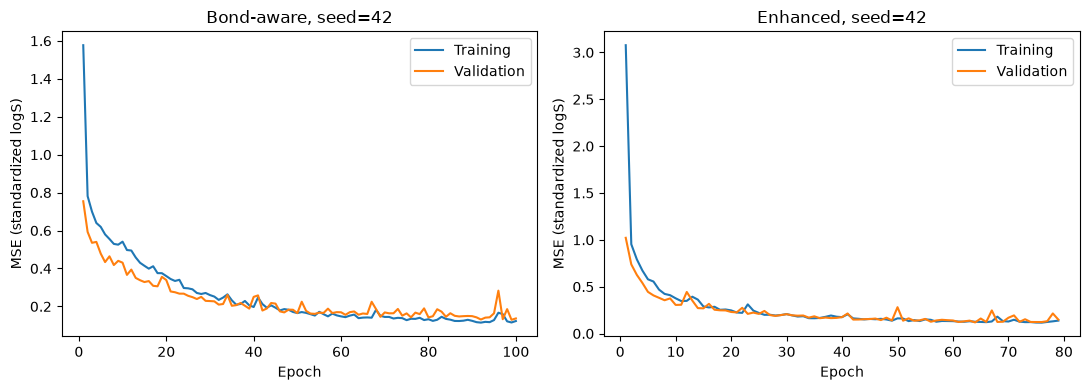

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for axis, input_dim, name in zip(axes, [10, 21], ["Bond-aware", "Enhanced"]):
    train_history, val_history = histories[(input_dim, 42)]
    epochs = np.arange(1, len(train_history) + 1)
    axis.plot(epochs, train_history, label="Training")
    axis.plot(epochs, val_history, label="Validation")
    axis.set(xlabel="Epoch", ylabel="MSE (standardized logS)", title=f"{name}, seed=42")
    axis.legend()
plt.tight_layout()
plt.show()